# Clasificación: KNN

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "knn"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,KNN
USAR_GPU,True
GPU detectada por librería,"xgboost: cuda, catboost: GPU, lightgbm: cuda"
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

KNN no admite pesos de clase (`KNeighborsClassifier` no tiene `class_weight`; su `weights` pondera a los vecinos por distancia, no por clase), así que de las estrategias de [manejo del desbalance](#mod-desbalance) solo se comparan el nativo y SMOTENC.

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 20 combinaciones aleatorias por estrategia. Se variaron el número de vecinos (k de 15 a 300), la ponderación de los vecinos (uniforme o por distancia) y la métrica de distancia (Manhattan con `p=1` o euclidiana con `p=2`).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
n_neighbors,entero entre 15 y 300
weights,"uniform, distance"
p,"1, 2"


### Validación Cruzada por Estrategia

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3907 ± 0.0447  (5 s)
✓ SMOTENC                PR-AUC = 0.3814 ± 0.0395  (2 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.391 ± 0.045,0.751 ± 0.031,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.836 ± 0.000,5.0
SMOTENC,0.381 ± 0.039,0.743 ± 0.027,0.304 ± 0.014,0.648 ± 0.051,0.414 ± 0.022,0.700 ± 0.007,2.0


Las dos estrategias obtienen una PR-AUC similar (0.391 ± 0.045 el nativo y 0.381 ± 0.039 SMOTENC). La diferencia (≈ 0.01) es mucho menor que la desviación entre folds y las desviaciones se solapan por completo. La ROC-AUC también es prácticamente la misma (0.751 ± 0.031 y 0.743 ± 0.027). La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo no predice ni un solo positivo en ningún fold: precision, recall y F1 valen 0.000 ± 0.000. Con k = 285 vecinos, la probabilidad estimada es, en esencia, la proporción (ponderada por distancia) de deprimidos entre esos vecinos, y con una prevalencia del 16% casi nunca supera 0.5. Por eso su accuracy de 0.836 ± 0.000 coincide exactamente con la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), y no refleja capacidad predictiva.

SMOTENC, al igualar las clases en el entrenamiento, eleva esas proporciones y alcanza un recall de 0.648 ± 0.051 con una precision de 0.304 ± 0.014 y un F1 de 0.414 ± 0.022. Su accuracy baja a 0.700 ± 0.007 por el aumento de falsos positivos en la clase mayoritaria.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,n_neighbors,p,weights
Estrategia,,,
Nativo (sin balanceo),285,1,distance
SMOTENC,285,1,distance


Las dos estrategias eligieron exactamente la misma configuración: k = 285 vecinos, distancia Manhattan (`p=1`) y ponderación por distancia. Un número de vecinos tan alto, cerca del límite superior del rango explorado (300), indica que el modelo prefiere promediar sobre vecindarios muy grandes, es decir, una frontera muy suave: la estructura local de los datos aporta poco y la señal es débil y ruidosa. Que el óptimo quede cerca del borde del rango sugiere que valores de k aún mayores podrían rendir igual o algo mejor.

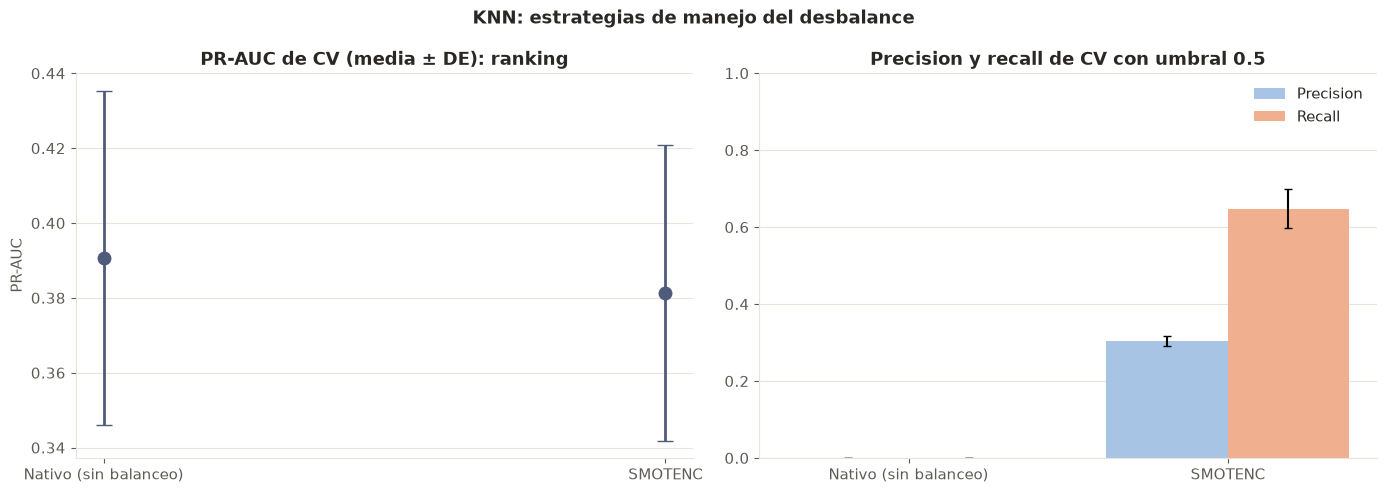

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las dos estrategias tienen una capacidad discriminativa equivalente. La PR-AUC media es muy parecida (~0.39 y ~0.38) y las barras de desviación se solapan casi por completo, así que SMOTENC no mejora la capacidad del KNN para ordenar los positivos por encima de los negativos. Lo que cambia es el punto de operación con el umbral fijo de 0.5: el nativo no predice ningún positivo (precision y recall de 0), mientras que SMOTENC desplaza las probabilidades hacia la clase positiva y lleva el recall a ~0.65 a costa de una precision de ~0.30.

### Selección del Mejor Modelo KNN

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,KNN
Estrategia ganadora,Nativo (sin balanceo)
PR-AUC de CV,0.3907 ± 0.0447
Hiperparámetros,"n_neighbors=285, p=1, weights=distance"
Criterio,Se elige 'nativo': tiene la mayor PR-AUC media de CV (0.3907 ± 0.0447).


Se elige el nativo, que tiene la PR-AUC media más alta (0.3907 ± 0.0447). Su ventaja sobre SMOTENC (0.0093) es mucho menor que la desviación entre folds, así que en la práctica las dos estrategias son equivalentes. Su recall de 0 con umbral 0.5 no es un problema para la selección, porque la PR-AUC solo depende de cómo se ordenan las probabilidades, pero indica que el umbral de operación que se optimice en la fase 3 tendrá que quedar muy por debajo de 0.5.

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)